# Machine Learning — Task 01: Data Preparation & Exploration
## Smart Traffic Accident Prediction

**Dataset:** Smart Traffic Management Dataset (Kaggle) — 2,000 traffic readings taken every minute at 5 locations.

**ML problem:** Predict whether an **accident is reported** (`accident_reported` = 1) at a location, using traffic, weather and signal conditions.

- **Task type:** Binary classification
- **Target (y):** `accident_reported` → 0 = no accident, 1 = accident
- **Features (X):** traffic volume, average speed, vehicle counts (cars / trucks / bikes), weather, temperature, humidity, signal status, location, time of day

**Notebook structure** (same order as the task sheet):
1. Data Understanding
2. Data Cleaning (missing values, duplicates, outlier detection, outlier treatment)
3. Exploratory Data Analysis (univariate, feature vs target, feature vs feature, correlation, groupby)
4. Summary of findings

## Library

In [1]:
# EDA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics & outlier detection
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

# 1) Data Understanding

### ❑ Read Data

In [2]:
# Read Data
data = pd.read_csv(r'Dataset/smart_traffic_management_dataset.csv')
df = data.copy()
df.head()

,timestamp,location_id,traffic_volume,avg_vehicle_speed,vehicle_count_cars,vehicle_count_trucks,vehicle_count_bikes,weather_condition,temperature,humidity,accident_reported,signal_status
0,2024-01-01 00:00:00,4,504,53.124162,142,24,44,Cloudy,33.334387,36.390698,0,Red
1,2024-01-01 00:01:00,5,209,44.947850,862,50,23,Cloudy,17.926830,37.640927,0,Green
2,2024-01-01 00:02:00,3,572,63.179229,317,12,10,Windy,33.483375,84.262610,1,Red
3,2024-01-01 00:03:00,5,699,42.269697,709,43,21,Sunny,19.212941,61.550978,0,Yellow
4,2024-01-01 00:04:00,5,639,72.185791,594,34,14,Cloudy,11.349244,77.494506,0,Red


**Observation:** The file loads correctly with a comma delimiter (no `delimiter=';'` needed). Each row is one reading at one location at one minute. We work on `df = data.copy()` so the original `data` stays untouched.

### ❑ Random Sample of Data

In [3]:
# Random Data
df.sample(5, random_state=42)

,timestamp,location_id,traffic_volume,avg_vehicle_speed,vehicle_count_cars,vehicle_count_trucks,vehicle_count_bikes,weather_condition,temperature,humidity,accident_reported,signal_status
1860,2024-01-02 07:00:00,3,775,27.522521,695,66,39,Cloudy,34.716889,49.877806,0,Yellow
353,2024-01-01 05:53:00,4,974,29.768903,602,40,36,Foggy,29.234894,77.412946,0,Red
1333,2024-01-01 22:13:00,1,453,57.587421,605,59,18,Cloudy,24.757800,85.274889,0,Red
905,2024-01-01 15:05:00,2,326,43.742478,376,16,9,Sunny,14.500451,49.550645,0,Green
1289,2024-01-01 21:29:00,5,243,68.297824,219,46,46,Windy,31.328633,33.745511,0,Red


**Observation:** Random rows look consistent with the first rows: integer counts, decimal speed/temperature/humidity, and text categories for weather and signal. No strange symbols or empty cells.

### ❑ Size of Data

In [4]:
# Size of Data
df.shape

(2000, 12)

**Observation:** **2,000 rows × 12 columns.** A small dataset — fine for classical ML models (KNN, Decision Tree, Naive Bayes), but every row matters, so we should avoid removing rows unless there is a strong reason.

### ❑ Information of Data

In [5]:
# Information of Data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   timestamp             2000 non-null   str    
 1   location_id           2000 non-null   int64  
 2   traffic_volume        2000 non-null   int64  
 3   avg_vehicle_speed     2000 non-null   float64
 4   vehicle_count_cars    2000 non-null   int64  
 5   vehicle_count_trucks  2000 non-null   int64  
 6   vehicle_count_bikes   2000 non-null   int64  
 7   weather_condition     2000 non-null   str    
 8   temperature           2000 non-null   float64
 9   humidity              2000 non-null   float64
 10  accident_reported     2000 non-null   int64  
 11  signal_status         2000 non-null   str    
dtypes: float64(3), int64(6), str(3)
memory usage: 187.6 KB


**Observation:**
- All 12 columns have **2,000 non-null** values → no missing data.
- `timestamp` is stored as text (`object`/`str`) → it must be converted to `datetime`.
- `weather_condition` and `signal_status` are text → **nominal categorical** features (they need encoding before modelling, in a later task).
- `location_id` is stored as a number but it is a **category code** (1–5), not a quantity. Location 4 is not "twice" location 2.
- `accident_reported` is stored as `int64` with values 0/1 → our **binary target**.
- Memory usage is very small (≈ 190 KB).

### ❑ Check Names Of columns

In [6]:
# Check Names Of columns
df.columns

Index(['timestamp', 'location_id', 'traffic_volume', 'avg_vehicle_speed',
       'vehicle_count_cars', 'vehicle_count_trucks', 'vehicle_count_bikes',
       'weather_condition', 'temperature', 'humidity', 'accident_reported',
       'signal_status'],
      dtype='str')

**Observation:** All names are lowercase snake_case, so naming is consistent. Points that are **unclear** and need a note:

| Column | Issue |
|---|---|
| `traffic_volume` | Not explained. It is **not** the sum of cars + trucks + bikes (checked in Data Cleaning), so it measures something different from the vehicle counts. |
| `avg_vehicle_speed` | No unit in the name. Values are 20–80, so we assume **km/h**. |
| `location_id` | A code only. We add a readable `location_name` label in Data Cleaning. |
| `accident_reported` | Clear: it is our target. |

No renaming is needed.

### ❑ Check Description

In [7]:
# Check Description
df.describe().T

,count,mean,std,min,25%,50%,75%,max
location_id,2000.0,2.991500,1.430892,1.000000,2.000000,3.000000,4.000000,5.000000
traffic_volume,2000.0,540.959000,271.933985,50.000000,309.000000,549.000000,774.000000,998.000000
avg_vehicle_speed,2000.0,50.009035,17.267898,20.011192,35.168589,50.412652,65.135366,79.972635
vehicle_count_cars,2000.0,449.872500,253.695741,20.000000,227.750000,452.000000,660.250000,899.000000
vehicle_count_trucks,2000.0,49.269000,28.830196,0.000000,24.000000,49.000000,74.000000,99.000000
vehicle_count_bikes,2000.0,24.117000,14.297011,0.000000,12.000000,24.000000,36.000000,49.000000
temperature,2000.0,22.447538,7.200535,10.025557,16.410169,22.364844,28.563564,34.990891
humidity,2000.0,60.105652,17.245294,30.007119,45.179396,60.450407,74.805580,89.989003
accident_reported,2000.0,0.054000,0.226074,0.000000,0.000000,0.000000,0.000000,1.000000


In [8]:
# Description of categorical columns
df.describe(include='object').T

,count,unique,top,freq
timestamp,2000,2000,2024-01-01 00:00:00,1
weather_condition,2000,5,Windy,438
signal_status,2000,3,Yellow,708


**Observation:**
- `avg_vehicle_speed`: 20 → 80 km/h, mean ≈ median ≈ 50 → no very slow or very fast vehicles.
- `traffic_volume`: 50 → 998, mean 541 ≈ median 549.
- `temperature`: 10 → 35 °C, `humidity`: 30 → 90 % → realistic weather ranges.
- `vehicle_count_trucks`: 0 → 99, `vehicle_count_bikes`: 0 → 49 → zero is a valid count, not a missing value.
- For every numeric column **mean ≈ median** and min/max are evenly spaced around them → distributions look **symmetric and flat (uniform)**. We confirm this with plots in the outlier section.
- `accident_reported` mean = **0.054** → only **5.4 %** of readings have an accident.
- No impossible values (negative speeds or counts, humidity above 100 %, etc.) — unlike the lecture's cardio dataset, where height = 55 cm and ap_hi = -150 were clearly wrong.

### ❑ Number of Unique Columns

In [9]:
# Number of Unique Columns
df.nunique()

timestamp               2000
location_id                5
traffic_volume           814
avg_vehicle_speed       2000
vehicle_count_cars       791
vehicle_count_trucks     100
vehicle_count_bikes       50
weather_condition          5
temperature             2000
humidity                2000
accident_reported          2
signal_status              3
dtype: int64

**Observation (high-cardinality fields):**
- `timestamp` → **2,000 unique values = one per row**. It acts like an ID, so it cannot be used as a raw feature; we extract the **hour** from it instead.
- `avg_vehicle_speed`, `temperature`, `humidity` → 2,000 unique values each. This is expected because they are continuous decimals.
- Low cardinality: `location_id` (5), `weather_condition` (5), `signal_status` (3), `accident_reported` (2) → categorical features.

### ❑ Check Balance Of Data

In [10]:
# Check Balance Of Data
df['accident_reported'].value_counts()

accident_reported
0    1892
1     108
Name: count, dtype: int64

In [11]:
# Check Balance Of Data
df['accident_reported'].value_counts(normalize=True) * 100

accident_reported
0    94.6
1     5.4
Name: proportion, dtype: float64

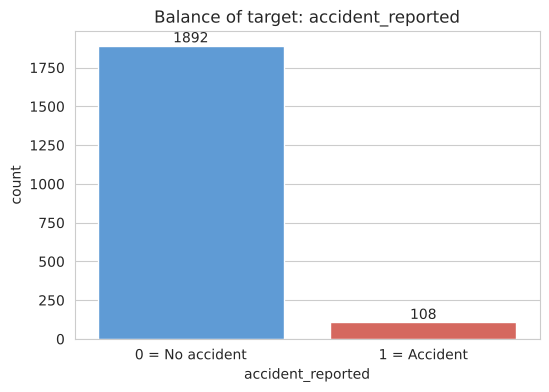

In [12]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='accident_reported', data=df, palette=['#4C9BE8', '#E8574C'])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Balance of target: accident_reported')
plt.xticks([0, 1], ['0 = No accident', '1 = Accident'])
plt.show()

**Observation:** The target is **highly imbalanced**: 1,892 no-accident rows (94.6 %) vs **108 accident rows (5.4 %)**, a ratio of about **17.5 : 1**.

Why this matters for the next tasks:
- A model that always predicts "no accident" would already score **94.6 % accuracy** while being useless. Accuracy alone is misleading here.
- We must evaluate with **precision, recall and F1-score** (Lecture 2 — Model Evaluation), focusing on recall of class 1.
- The train/test split must be **stratified** so both sets keep the 5.4 % ratio.
- Balancing options for later: `class_weight='balanced'`, oversampling the minority class, or undersampling the majority class.

# 2) Data Cleaning

### ❑ Check Null (Missing Values)

In [13]:
# Check Null (Missing Values)
df.isna().sum()

timestamp               0
location_id             0
traffic_volume          0
avg_vehicle_speed       0
vehicle_count_cars      0
vehicle_count_trucks    0
vehicle_count_bikes     0
weather_condition       0
temperature             0
humidity                0
accident_reported       0
signal_status           0
dtype: int64

**Observation & decision:** **0 missing values in every column**, so no rows are dropped and no imputation is needed.

If missing values had appeared, the plan (from the lecture's comparison of imputation methods) would be:

| Column type | Method | Reason |
|---|---|---|
| Continuous numeric (speed, volume, temperature, humidity) | **Median** | Robust to outliers; our columns are not normally distributed |
| Counts (cars, trucks, bikes) | **Median** | Discrete and possibly skewed |
| Categorical (weather, signal, location) | **Most frequent (mode)** | Mean/median make no sense for categories |
| Target (`accident_reported`) | **Drop the row** | We must never guess the label |

### ❑ Detect and drop duplicate rows

In [14]:
# Check Duplicated Values
print(f' Duplicated = {df.duplicated().sum()} \n===================================')
df[df.duplicated()]

 Duplicated = 0 


,timestamp,location_id,traffic_volume,avg_vehicle_speed,vehicle_count_cars,vehicle_count_trucks,vehicle_count_bikes,weather_condition,temperature,humidity,accident_reported,signal_status


In [15]:
# Check duplicates ignoring timestamp (same reading recorded twice at different times)
print(f' Duplicated (without timestamp) = {df.drop(columns="timestamp").duplicated().sum()}')

 Duplicated (without timestamp) = 0


In [16]:
# Drop Duplicated
df = df.drop_duplicates()
print(f' Duplicated = {df.duplicated().sum()} \n===================================')
print('Shape after dropping duplicates:', df.shape)

 Duplicated = 0 
Shape after dropping duplicates: (2000, 12)


**Observation & decision:** **0 duplicate rows**, even when the timestamp is ignored. `drop_duplicates()` is still run as a safety step; the shape stays (2000, 12).

### ❑ Fix timestamp Data Type (text → datetime) & Extract Hour
`df.info()` showed that `timestamp` is stored as **text**, not as a date. We convert it to `datetime` so we can read the hour from it.

In [17]:
# Convert timestamp from text to datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

print('First reading :', df['timestamp'].min())
print('Last reading  :', df['timestamp'].max())
print('Time step     :', df['timestamp'].diff().mode()[0])
df['timestamp'].dtype

First reading : 2024-01-01 00:00:00
Last reading  : 2024-01-02 09:19:00
Time step     : 0 days 00:01:00


dtype('<M8[us]')

In [18]:
# Extract useful time features
df['hour'] = df['timestamp'].dt.hour
df['is_peak_hour'] = df['hour'].isin([7, 8, 9, 16, 17, 18, 19]).astype(int)

# Readable label for location_id (used only for plots / tables)
location_map = {1: 'Ring Road Cairo', 2: 'Corniche Alexandria', 3: 'Suez Road',
                4: 'October Bridge', 5: 'Tahrir Square'}
df['location_name'] = df['location_id'].map(location_map)

# Total of the three vehicle counts
df['total_vehicles'] = df['vehicle_count_cars'] + df['vehicle_count_trucks'] + df['vehicle_count_bikes']

df[['timestamp', 'hour', 'is_peak_hour', 'location_id', 'location_name', 'total_vehicles']].head()

,timestamp,hour,is_peak_hour,location_id,location_name,total_vehicles
0,2024-01-01 00:00:00,0,0,4,October Bridge,210
1,2024-01-01 00:01:00,0,0,5,Tahrir Square,935
2,2024-01-01 00:02:00,0,0,3,Suez Road,339
3,2024-01-01 00:03:00,0,0,5,Tahrir Square,773
4,2024-01-01 00:04:00,0,0,5,Tahrir Square,642


**Observation:**
- The data covers only **about 33 hours** (2024-01-01 00:00 → 2024-01-02 09:19), one reading per minute. Day, month and year are constant, so only the **hour** is useful.
- Hours 0–8 appear on both days (120 readings each) while hours 10–23 appear once (60 each), so hour coverage is uneven.
- `is_peak_hour` = 1 for rush hours (7–9 AM and 4–7 PM).
- `location_name` maps the 5 codes to readable names. It is a **label only** (the dataset does not give real place names); for modelling, `location_id` will be one-hot encoded.

### ❑ Consistency Check: `traffic_volume` vs vehicle counts

In [19]:
same = (df['total_vehicles'] == df['traffic_volume']).sum()
bigger = (df['total_vehicles'] > df['traffic_volume']).mean() * 100
print(f'Rows where cars+trucks+bikes == traffic_volume : {same}')
print(f'Rows where cars+trucks+bikes  > traffic_volume : {bigger:.1f} %')
print('Correlation:', round(df['total_vehicles'].corr(df['traffic_volume']), 3))

Rows where cars+trucks+bikes == traffic_volume : 1
Rows where cars+trucks+bikes  > traffic_volume : 47.9 %
Correlation: 0.012


**Observation & decision:** `traffic_volume` matches the sum of the vehicle counts in only **1 row**, and in **48 %** of rows the counts are *larger* than the volume. Their correlation is ≈ 0. So `traffic_volume` is **not** a total of the counts; it is a separate measurement (for example, flow over a different time window). We **keep both** and do not "fix" either one, because we have no information about which is correct, and we document this as a data-quality limitation.

### ❑ Categorical Values Check

In [20]:
for col in ['location_name', 'weather_condition', 'signal_status']:
    print(df[col].value_counts(), '\n')

location_name
Ring Road Cairo        415
Tahrir Square          409
Corniche Alexandria    401
October Bridge         396
Suez Road              379
Name: count, dtype: int64 

weather_condition
Windy     438
Cloudy    424
Rainy     387
Sunny     378
Foggy     373
Name: count, dtype: int64 

signal_status
Yellow    708
Red       683
Green     609
Name: count, dtype: int64 



**Observation:** No spelling variants (e.g. "rainy" vs "Rainy") and no unexpected categories. The categories are fairly evenly spread (each location ≈ 400 rows, each weather 373–438 rows, each signal 609–708 rows), so no rare-category grouping is needed.

## ❑ Outlier Detection (part of Data Cleaning)
### ❑ Select Method
Following the lecture flowchart: **Shape of data?**
- **1D (one feature at a time)** → IQR rule or Z-score
- **Multi-D (several features together)** → no clear clusters → Isolation Forest; clusters → LOF / DBSCAN

We check the **continuous** features only. `location_id`, `accident_reported` and `is_peak_hour` are categories/flags, so "outlier" has no meaning for them.

In [21]:
num_cols = ['traffic_volume', 'avg_vehicle_speed', 'vehicle_count_cars', 'vehicle_count_trucks',
            'vehicle_count_bikes', 'temperature', 'humidity']
num_cols

['traffic_volume',
 'avg_vehicle_speed',
 'vehicle_count_cars',
 'vehicle_count_trucks',
 'vehicle_count_bikes',
 'temperature',
 'humidity']

### ❑ Check Normal Distribution

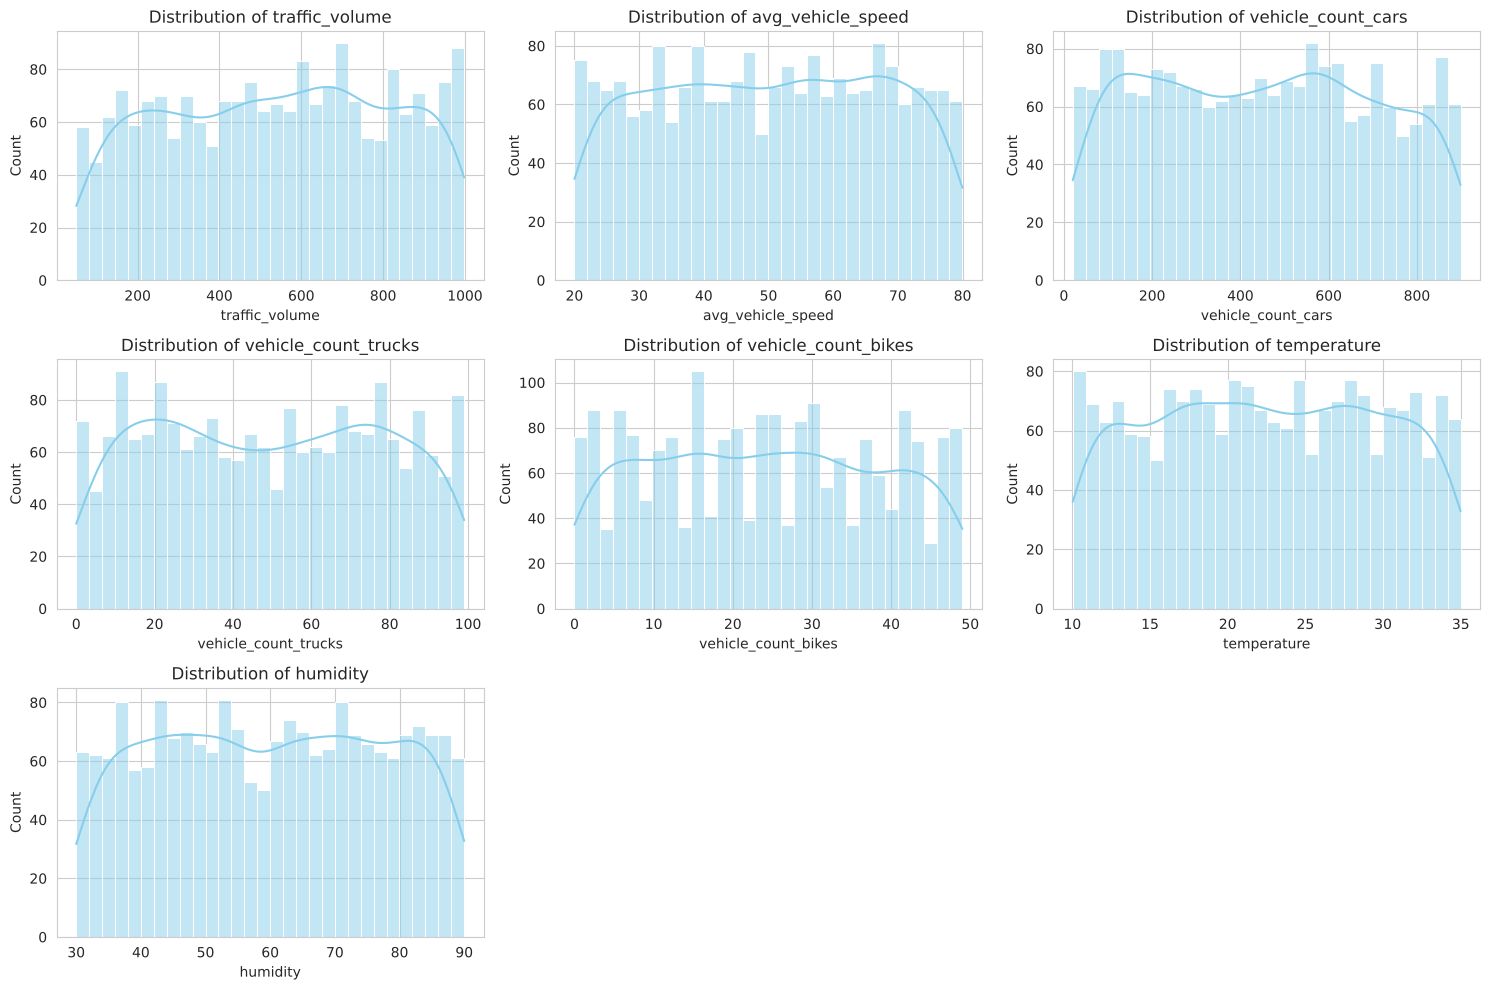

In [22]:
# Check Normal Distrbution
plt.figure(figsize=(15, 10))
for i, feature in enumerate(num_cols):
    plt.subplot(3, 3, i + 1)
    sns.histplot(df[feature], kde=True, bins=30, color="skyblue")
    plt.title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

In [23]:
# Skewness and normality test (Shapiro-Wilk: p < 0.05 means NOT normal)
pd.DataFrame({
    'skewness': df[num_cols].skew().round(3),
    'shapiro_p_value': [stats.shapiro(df[c])[1] for c in num_cols]
})

,skewness,shapiro_p_value
traffic_volume,-0.052,7.603181e-24
avg_vehicle_speed,-0.024,3.156377e-24
vehicle_count_cars,0.044,1.673159e-24
vehicle_count_trucks,0.018,5.118306e-25
vehicle_count_bikes,0.042,7.636142e-24
temperature,-0.003,5.994480e-24
humidity,-0.003,1.568902e-24


**Observation:** All seven features look **flat (uniform)**, not bell-shaped. Skewness is ≈ 0 (no long tails), but the Shapiro-Wilk p-values are far below 0.05, so **none of them is normally distributed**.

**Method choice:** The **Z-score** method assumes a normal distribution, so it is not ideal here. The **IQR rule** makes no normality assumption, so it is our **main 1D method**. We still run the Z-score as a second check.

### ❑ 1 - IQR Rule (Interquartile Range Rule)
Outlier if value < **Q1 − 1.5·IQR** or value > **Q3 + 1.5·IQR**, where IQR = Q3 − Q1.

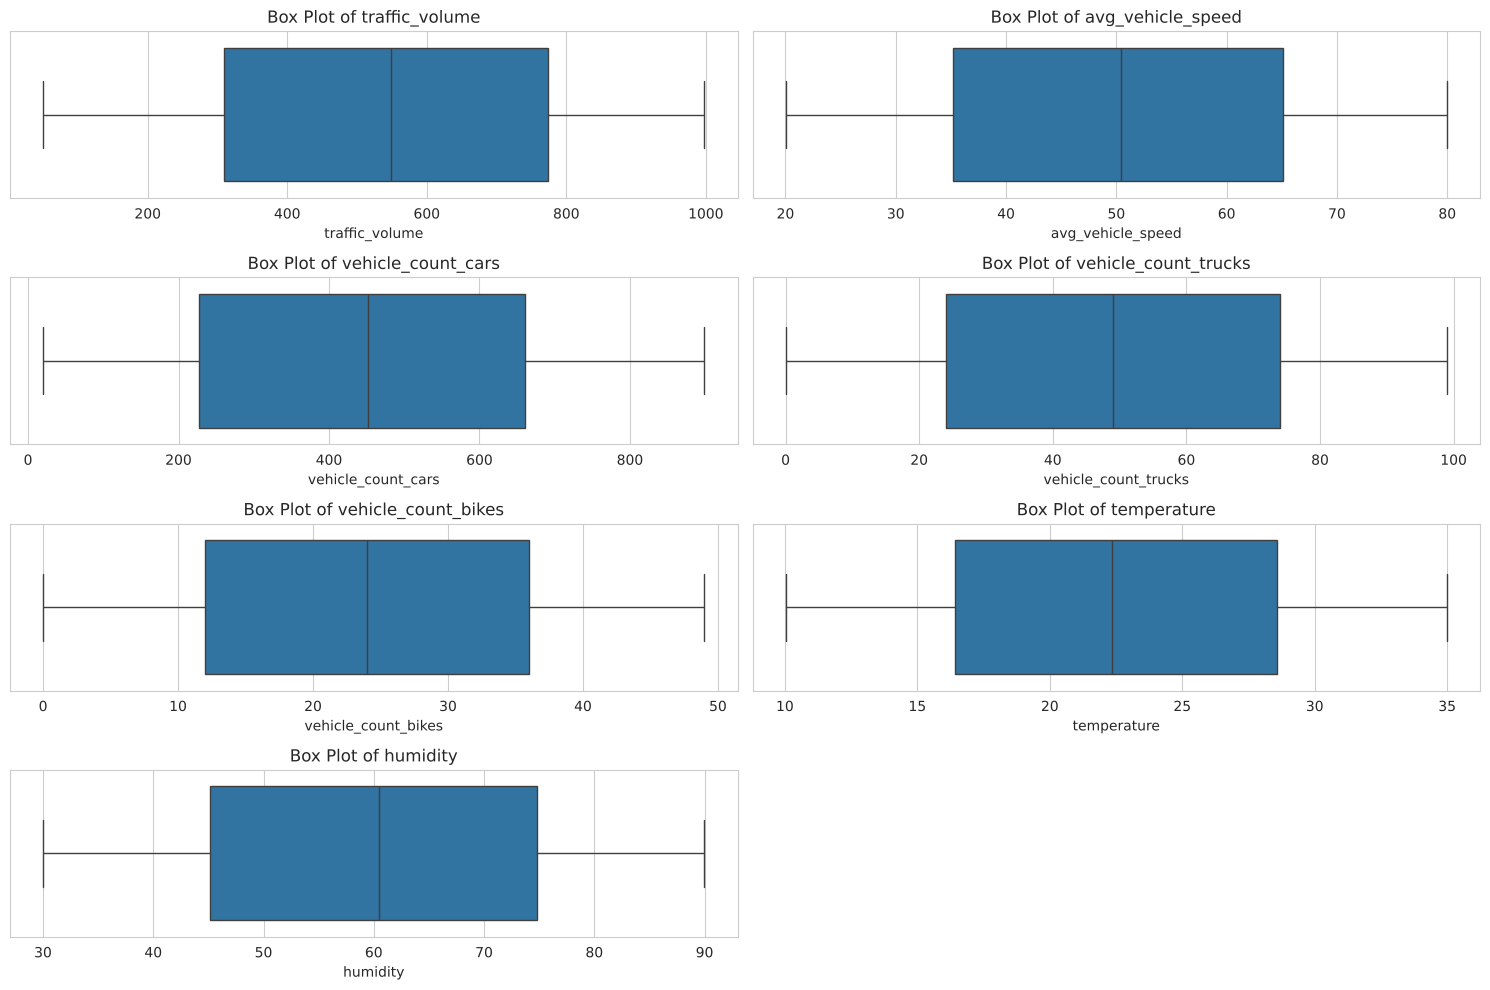

In [24]:
# Check Outlier
plt.figure(figsize=(15, 10))
for i, feature in enumerate(num_cols):
    plt.subplot(4, 2, i + 1)
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
plt.tight_layout()
plt.show()

In [25]:
# Count IQR outliers per feature
iqr_table = []
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    iqr_table.append([col, round(lower, 2), round(upper, 2), df[col].min(), df[col].max(), n_out])

pd.DataFrame(iqr_table, columns=['feature', 'lower_limit', 'upper_limit', 'min', 'max', 'n_outliers'])

,feature,lower_limit,upper_limit,min,max,n_outliers
0,traffic_volume,-388.50,1471.50,50.000000,998.000000,0
1,avg_vehicle_speed,-9.78,110.09,20.011192,79.972635,0
2,vehicle_count_cars,-421.00,1309.00,20.000000,899.000000,0
3,vehicle_count_trucks,-51.00,149.00,0.000000,99.000000,0
4,vehicle_count_bikes,-24.00,72.00,0.000000,49.000000,0
5,temperature,-1.82,46.79,10.025557,34.990891,0
6,humidity,0.74,119.24,30.007119,89.989003,0


**Observation:** No box plot shows points beyond the whiskers, and the table confirms **0 IQR outliers** in every feature. Each feature's real min/max lies **inside** its IQR limits.

### ❑ 2 - Check Outlier (Z – Score)

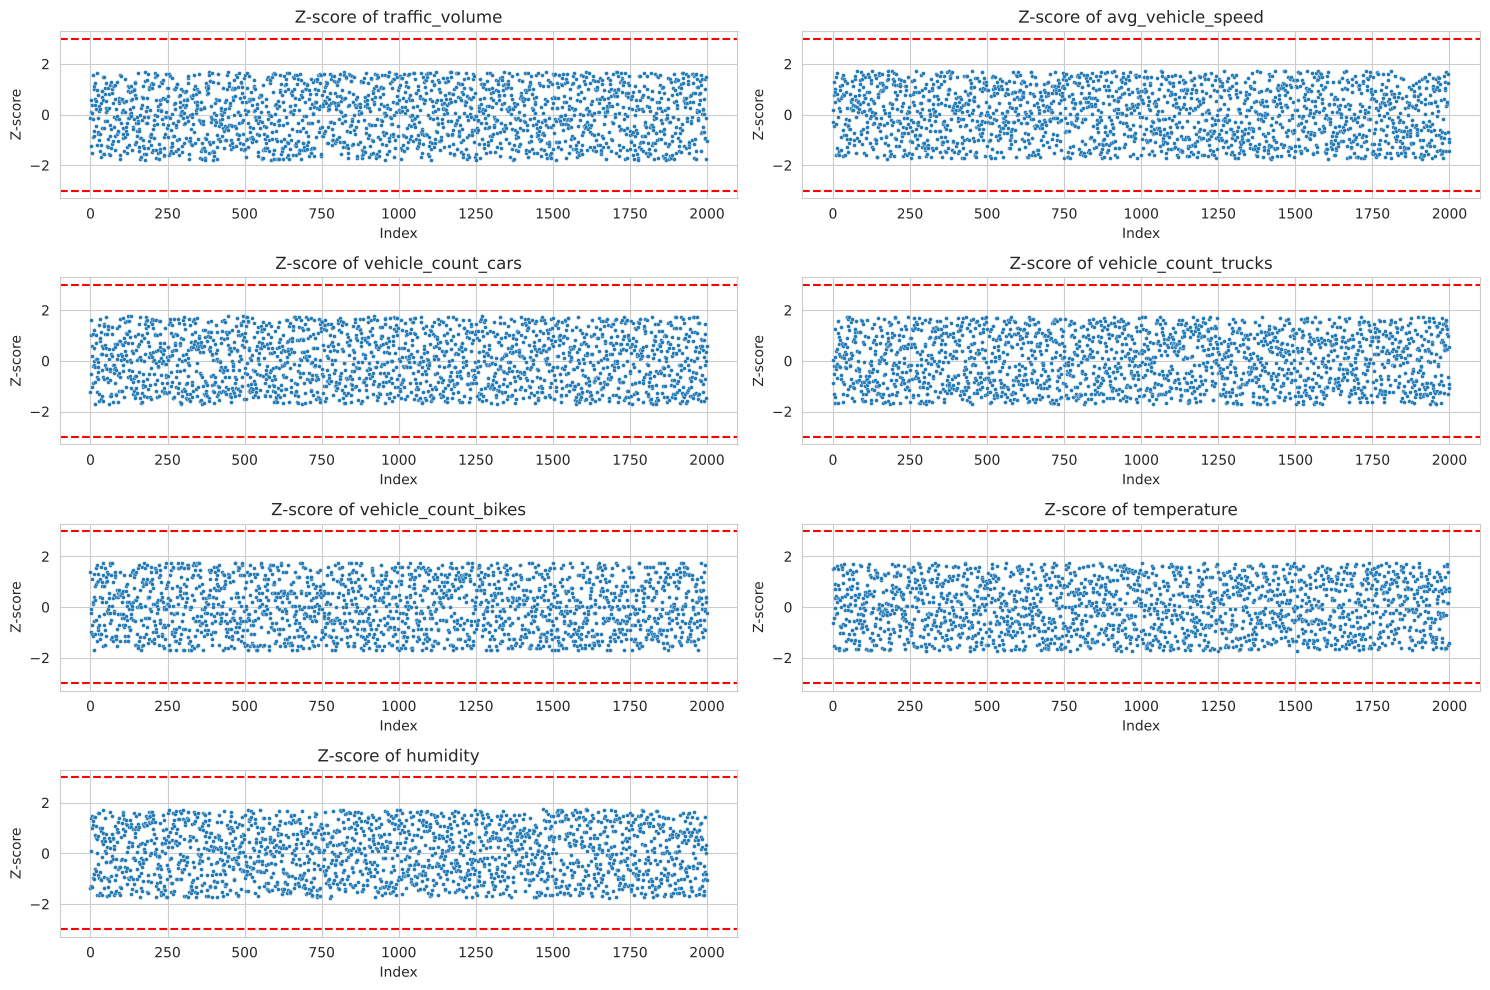

In [26]:
plt.figure(figsize=(15, 10))

for i, feature in enumerate(num_cols):
    plt.subplot(4, 2, i + 1)

    # Calculate Z-score
    z_scores = stats.zscore(df[feature])

    # (Scatter plot Z-scores)
    sns.scatterplot(x=np.arange(len(z_scores)), y=z_scores, s=8)

    # (Outlier threshold)
    plt.axhline(y=3, color='red', linestyle='--')
    plt.axhline(y=-3, color='red', linestyle='--')

    plt.title(f'Z-score of {feature}')
    plt.xlabel("Index")
    plt.ylabel("Z-score")

plt.tight_layout()
plt.show()

In [27]:
z_counts = {col: (np.abs(stats.zscore(df[col])) > 3).sum() for col in num_cols}
z_max = {col: round(np.abs(stats.zscore(df[col])).max(), 2) for col in num_cols}
pd.DataFrame({'n_outliers_|z|>3': z_counts, 'max_|z|': z_max})

,n_outliers_|z|>3,max_|z|
traffic_volume,0,1.81
avg_vehicle_speed,0,1.74
vehicle_count_cars,0,1.77
vehicle_count_trucks,0,1.73
vehicle_count_bikes,0,1.74
temperature,0,1.74
humidity,0,1.75


**Observation:** Every point stays between the red lines (−3 and +3). The largest |z| is only about 1.7–1.8 (a flat/uniform distribution cannot produce values much beyond ±1.8), so the Z-score also finds **0 outliers**. Both 1D methods agree.

### ❑ 3 - Isolation Forest & 4 - Local Outlier Factor (Multi-D check)
A row can look normal in each column separately but be unusual as a **combination**. We scale the features first (they have very different ranges) and then run the two multi-dimensional methods.

In [28]:
X_scaled = StandardScaler().fit_transform(df[num_cols])

# Isolation Forest: we must choose a contamination rate (expected % of outliers) -> 1 %
iso = IsolationForest(contamination=0.01, random_state=42)
df['iso_outlier'] = iso.fit_predict(X_scaled)          # -1 = outlier, 1 = normal

# Local Outlier Factor: compares each point's local density with its neighbours
lof = LocalOutlierFactor(n_neighbors=20)
df['lof_outlier'] = lof.fit_predict(X_scaled)          # -1 = outlier, 1 = normal

print('Isolation Forest outliers :', (df['iso_outlier'] == -1).sum())
print('LOF outliers              :', (df['lof_outlier'] == -1).sum())

Isolation Forest outliers : 20
LOF outliers              : 0


In [29]:
# Are the Isolation Forest rows really abnormal? Compare their ranges with the full data
pd.concat([df[num_cols].agg(['min', 'max']).T.add_prefix('all_'),
           df.loc[df['iso_outlier'] == -1, num_cols].agg(['min', 'max']).T.add_prefix('flagged_')], axis=1)

,all_min,all_max,flagged_min,flagged_max
traffic_volume,50.000000,998.000000,62.000000,989.000000
avg_vehicle_speed,20.011192,79.972635,21.103169,79.644899
vehicle_count_cars,20.000000,899.000000,33.000000,893.000000
vehicle_count_trucks,0.000000,99.000000,0.000000,99.000000
vehicle_count_bikes,0.000000,49.000000,0.000000,49.000000
temperature,10.025557,34.990891,10.025557,34.921222
humidity,30.007119,89.989003,31.244481,89.414273


**Observation:**
- **LOF finds 0 outliers.** The points are spread evenly, so no point is in a much emptier area than its neighbours.
- **Isolation Forest flags 20 rows, but only because we told it to** (`contamination=0.01` forces it to pick the "most isolated" 1 %). The flagged rows' values are all **inside the normal min–max ranges**; they are rows that sit near the edges of several features at the same time, not errors.
- Isolation Forest is not really needed here, because the 1D methods and LOF already agree that the data is clean.

In [30]:
# Remove helper columns
df = df.drop(columns=['iso_outlier', 'lof_outlier'])

### ❑ Domain (Logical) Check

In [31]:
checks = {
    'speed outside 0-200 km/h': ((df['avg_vehicle_speed'] < 0) | (df['avg_vehicle_speed'] > 200)).sum(),
    'negative vehicle counts': (df[['vehicle_count_cars', 'vehicle_count_trucks', 'vehicle_count_bikes']] < 0).any(axis=1).sum(),
    'humidity outside 0-100 %': ((df['humidity'] < 0) | (df['humidity'] > 100)).sum(),
    'temperature outside -20..55 C': ((df['temperature'] < -20) | (df['temperature'] > 55)).sum(),
    'traffic_volume <= 0': (df['traffic_volume'] <= 0).sum(),
}
pd.Series(checks, name='invalid_rows')

speed outside 0-200 km/h         0
negative vehicle counts          0
humidity outside 0-100 %         0
temperature outside -20..55 C    0
traffic_volume <= 0              0
Name: invalid_rows, dtype: int64

**Observation:** **0 physically impossible values.** Statistical methods and common-sense limits agree.

## ❑ Outliers Treatment Techniques
| Technique | What it does | Fits our data? |
|---|---|---|
| **1) Remove** | Delete outlier rows (IQR filter) | ❌ Nothing to remove, and with only 108 accident rows we cannot afford to lose data |
| **2) Transformation** (log, √, Box-Cox, Yeo-Johnson) | Reduces skew and pulls in long tails | ❌ Skewness ≈ 0 and there are no tails; a log would distort flat distributions |
| **3) Imputation** | Replace outliers with median/mean | ❌ No outlier values to replace |
| **4) Ignoring (keep)** | Leave values as they are | ✅ **Chosen** — every value is valid and inside its IQR limits |
| **5) Capping** (winsorizing) | Clip values to the IQR limits | ❌ Would change nothing; min/max are already inside the limits |

**Decision: Ignore (keep all values).** The proof is below: the lecture's IQR removal code removes **0 rows**, and capping changes **0 values**.

*Note for the modelling task:* the features have very different ranges (bikes 0–49 vs cars 20–899), so **scaling** (StandardScaler / MinMaxScaler) will be needed for distance-based models like **KNN**. That is a scaling step, not an outlier step.

In [32]:
# Remove Outliers Use IQR (lecture method) -> proof that it removes nothing
df_no_outliers = df.copy()
for col in num_cols:
    Q1 = df_no_outliers[col].quantile(0.25)
    Q3 = df_no_outliers[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df_no_outliers = df_no_outliers[(df_no_outliers[col] >= lower) & (df_no_outliers[col] <= upper)]

print("Original data shape:", df.shape)
print("Data shape after removing outliers:", df_no_outliers.shape)

Original data shape: (2000, 16)
Data shape after removing outliers: (2000, 16)


In [33]:
# Capping -> proof that it changes nothing
changed = 0
for col in num_cols:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    capped = df[col].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)
    changed += (capped != df[col]).sum()
print('Values changed by capping:', changed)

Values changed by capping: 0


# 3) Exploratory Data Analysis (EDA)

## 1. Univariate Analysis

### Numerical features

In [34]:
uni_cols = num_cols + ['total_vehicles']
summary = df[uni_cols].agg(['mean', 'median', 'std', 'min', 'max', 'skew']).T
summary['range'] = summary['max'] - summary['min']
summary.round(2)

,mean,median,std,min,max,skew,range
traffic_volume,540.96,549.00,271.93,50.00,998.00,-0.05,948.00
avg_vehicle_speed,50.01,50.41,17.27,20.01,79.97,-0.02,59.96
vehicle_count_cars,449.87,452.00,253.70,20.00,899.00,0.04,879.00
vehicle_count_trucks,49.27,49.00,28.83,0.00,99.00,0.02,99.00
vehicle_count_bikes,24.12,24.00,14.30,0.00,49.00,0.04,49.00
temperature,22.45,22.36,7.20,10.03,34.99,-0.00,24.97
humidity,60.11,60.45,17.25,30.01,89.99,-0.00,59.98
total_vehicles,523.26,527.00,255.05,39.00,1034.00,0.04,995.00


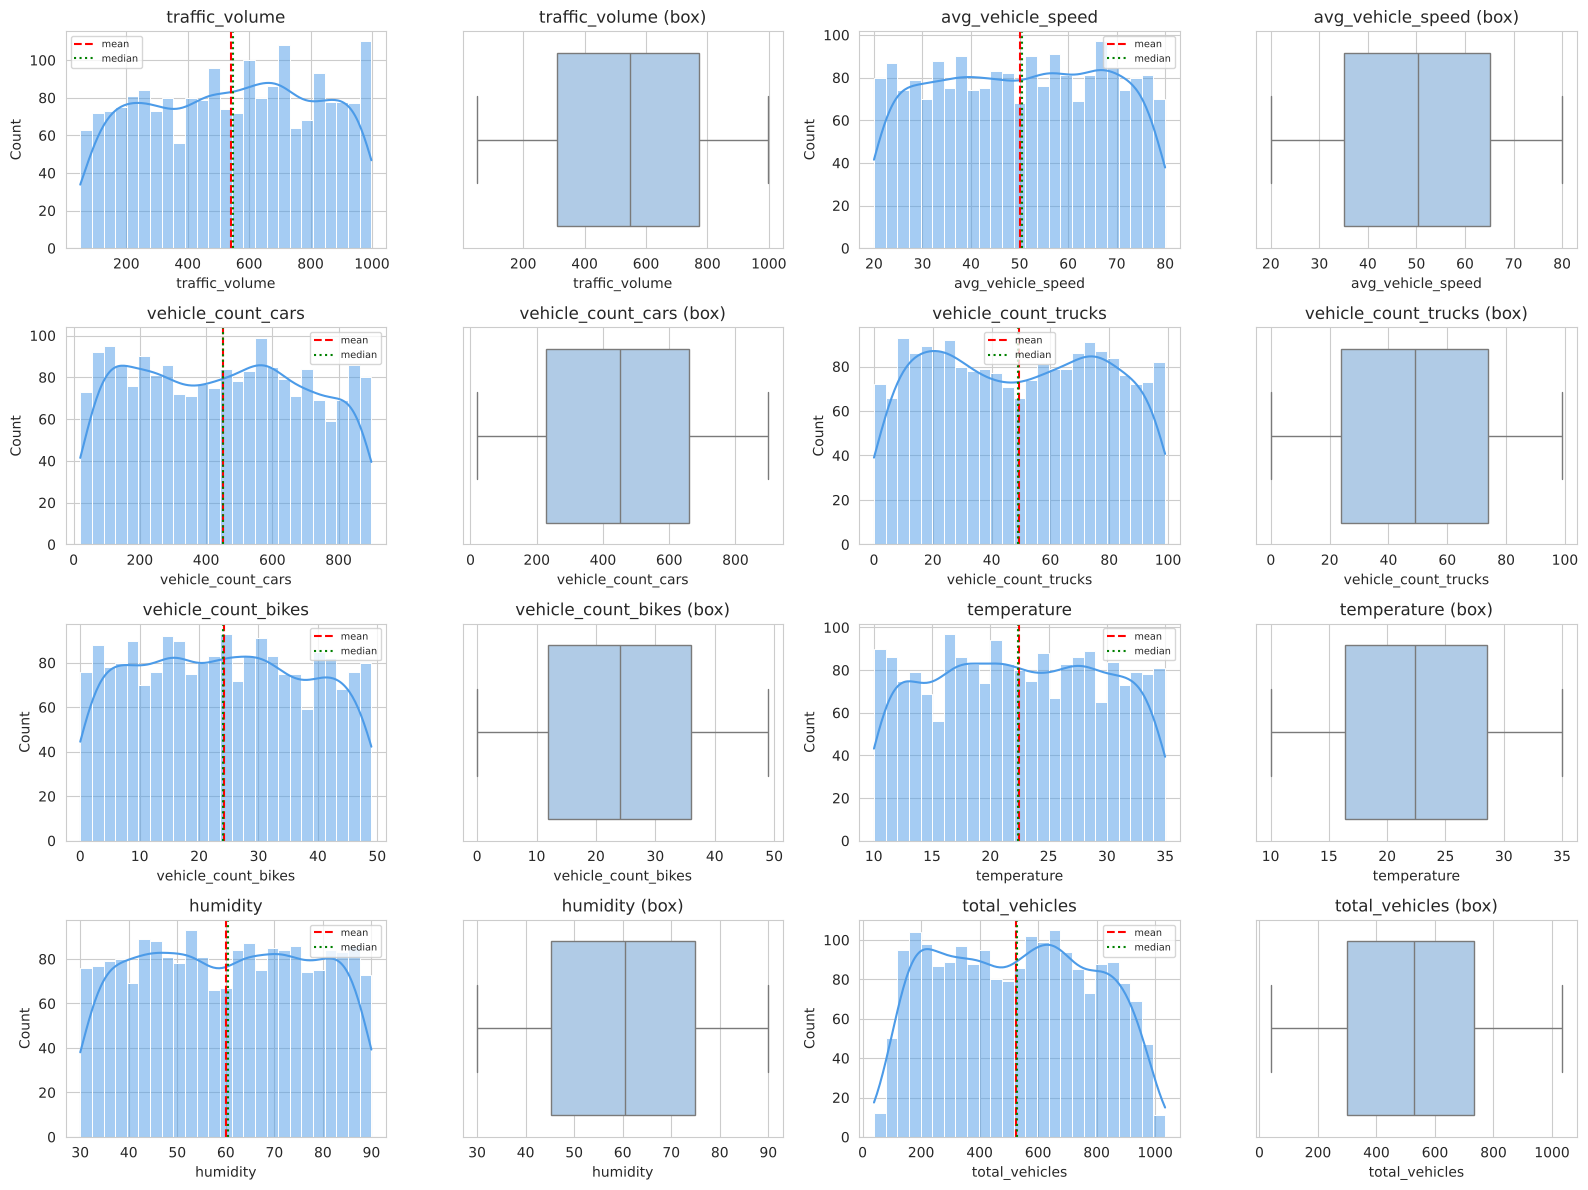

In [35]:
plt.figure(figsize=(16, 12))
for i, feature in enumerate(uni_cols):
    plt.subplot(4, 4, 2 * i + 1)
    sns.histplot(df[feature], kde=True, bins=25, color='#4C9BE8')
    plt.axvline(df[feature].mean(), color='red', linestyle='--', label='mean')
    plt.axvline(df[feature].median(), color='green', linestyle=':', label='median')
    plt.title(feature)
    plt.legend(fontsize=7)
    plt.subplot(4, 4, 2 * i + 2)
    sns.boxplot(x=df[feature], color='#A7CBEF')
    plt.title(f'{feature} (box)')
plt.tight_layout()
plt.show()

**Observation:**
- **Central tendency:** mean and median are almost equal for every feature (e.g. speed 50.0 vs 50.4, volume 541 vs 549) → symmetric distributions.
- **Spread:** wide and even. Speed std = 17.3 km/h over a 20–80 range; volume std = 272 over 50–998.
- **Shape:** every original feature is close to **uniform** (every value is about equally likely). Real traffic usually shows peaks (for example, many readings around a typical speed), so this is a strong sign that the Kaggle dataset is **synthetic**.
- `total_vehicles` is roughly uniform as well and is dominated by cars (cars are ≈ 86 % of the total on average).

### Categorical features

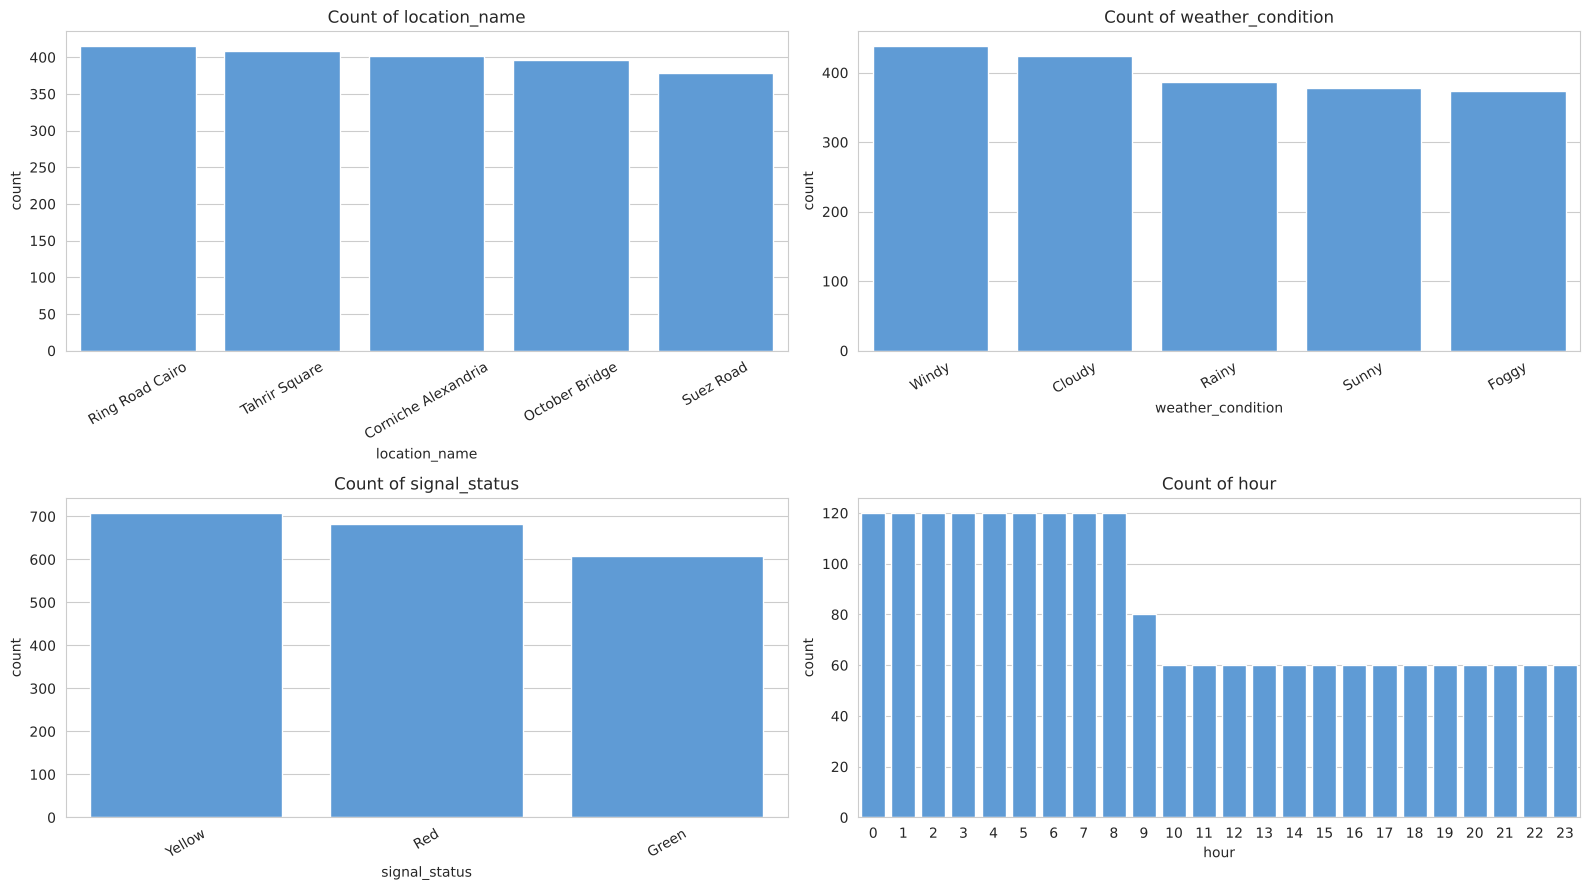

In [36]:
cat_cols = ['location_name', 'weather_condition', 'signal_status', 'hour']
plt.figure(figsize=(16, 9))
for i, col in enumerate(cat_cols):
    plt.subplot(2, 2, i + 1)
    order = sorted(df[col].unique()) if col == 'hour' else df[col].value_counts().index
    sns.countplot(x=col, data=df, order=order, color='#4C9BE8')
    plt.title(f'Count of {col}')
    plt.xticks(rotation=30 if col != 'hour' else 0)
plt.tight_layout()
plt.show()

**Observation:** Locations (379–415 rows), weather types (373–438) and signal states (609–708) are **roughly balanced**, so every category has enough samples to compare. Hour counts are uneven only because hours 0–8 were recorded on two days.

## 2. Feature vs. Target Analysis

### Numerical features vs `accident_reported`

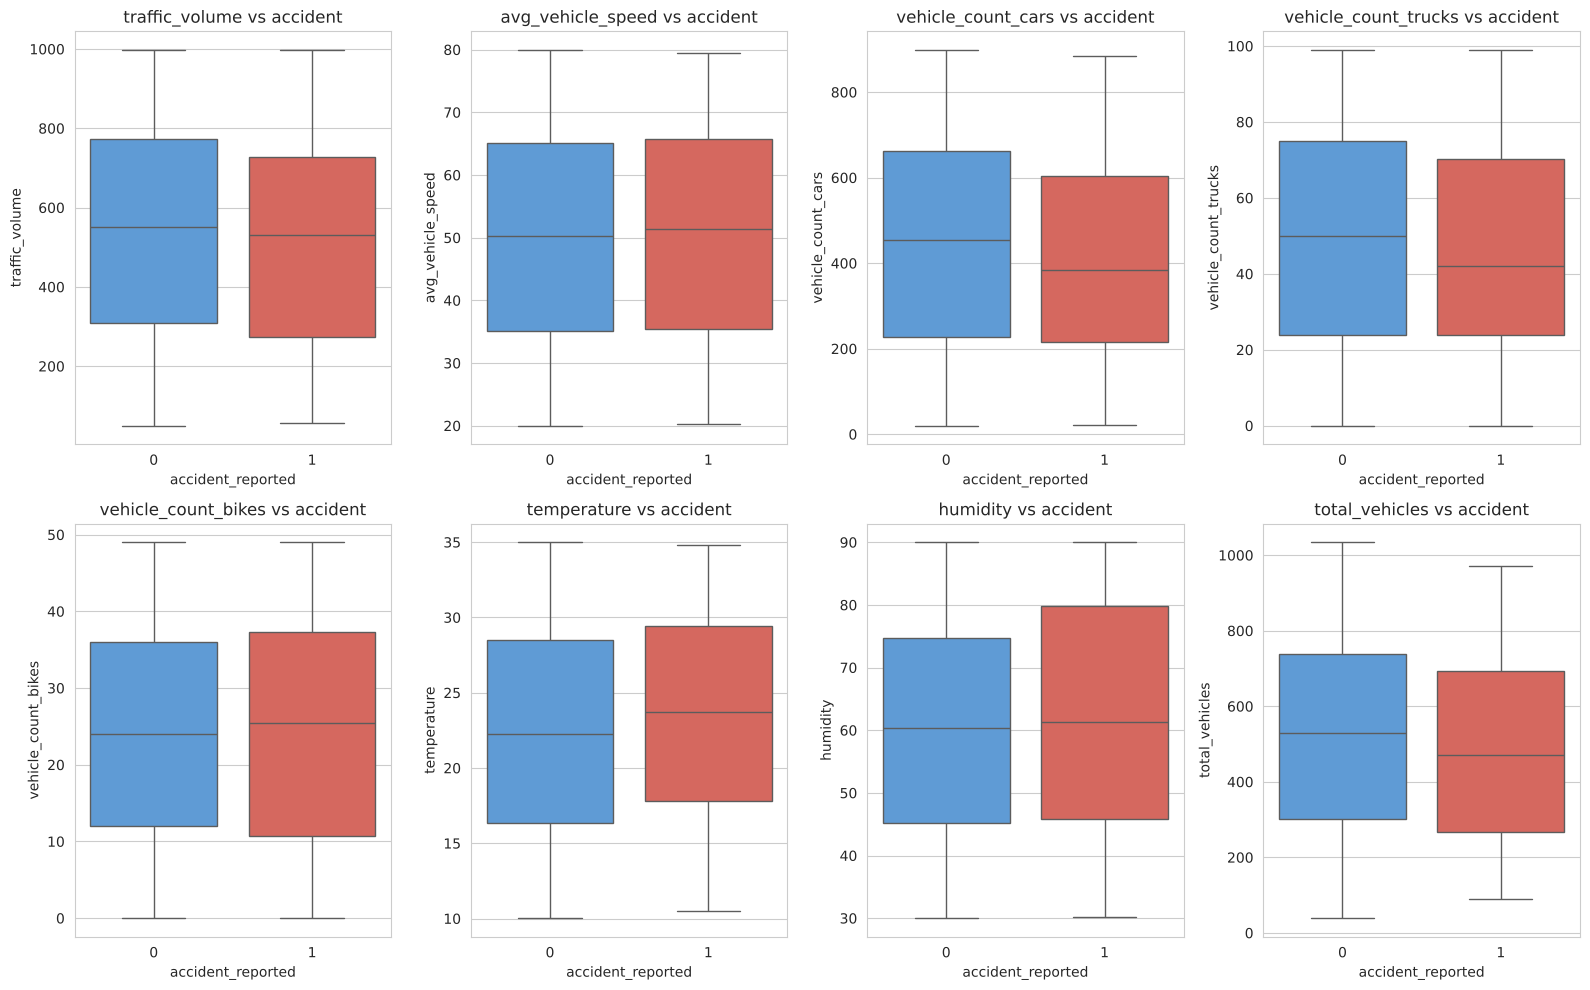

In [37]:
plt.figure(figsize=(16, 10))
for i, feature in enumerate(uni_cols):
    plt.subplot(2, 4, i + 1)
    sns.boxplot(x='accident_reported', y=feature, data=df, palette=['#4C9BE8', '#E8574C'])
    plt.title(f'{feature} vs accident')
plt.tight_layout()
plt.show()

In [38]:
# Mean of each feature per class + Mann-Whitney U test (p < 0.05 = significant difference)
rows = []
for col in uni_cols + ['hour']:
    no_acc = df.loc[df['accident_reported'] == 0, col]
    acc = df.loc[df['accident_reported'] == 1, col]
    rows.append([col, round(no_acc.mean(), 2), round(acc.mean(), 2),
                 round(stats.mannwhitneyu(acc, no_acc).pvalue, 3)])
pd.DataFrame(rows, columns=['feature', 'mean_no_accident', 'mean_accident', 'p_value'])

,feature,mean_no_accident,mean_accident,p_value
0,traffic_volume,541.94,523.77,0.493
1,avg_vehicle_speed,49.96,50.82,0.602
2,vehicle_count_cars,451.99,412.76,0.120
3,vehicle_count_trucks,49.51,44.99,0.118
4,vehicle_count_bikes,24.09,24.55,0.765
5,temperature,22.38,23.68,0.071
6,humidity,60.04,61.29,0.468
7,total_vehicles,525.60,482.30,0.088
8,hour,9.42,10.00,0.393


**Observation:**
- The boxes for class 0 and class 1 **overlap almost completely** for every feature.
- Accident rows have slightly **fewer cars** (413 vs 452) and slightly **higher temperature** (23.7 vs 22.4 °C), but the p-values (0.12 and 0.07) are above 0.05, so these differences could be **random chance**.
- **No numerical feature has a statistically significant link with accidents.** Speed is almost identical in both groups (50.8 vs 50.0 km/h), so in this data speeding does not explain accidents.

### Categorical features vs `accident_reported`

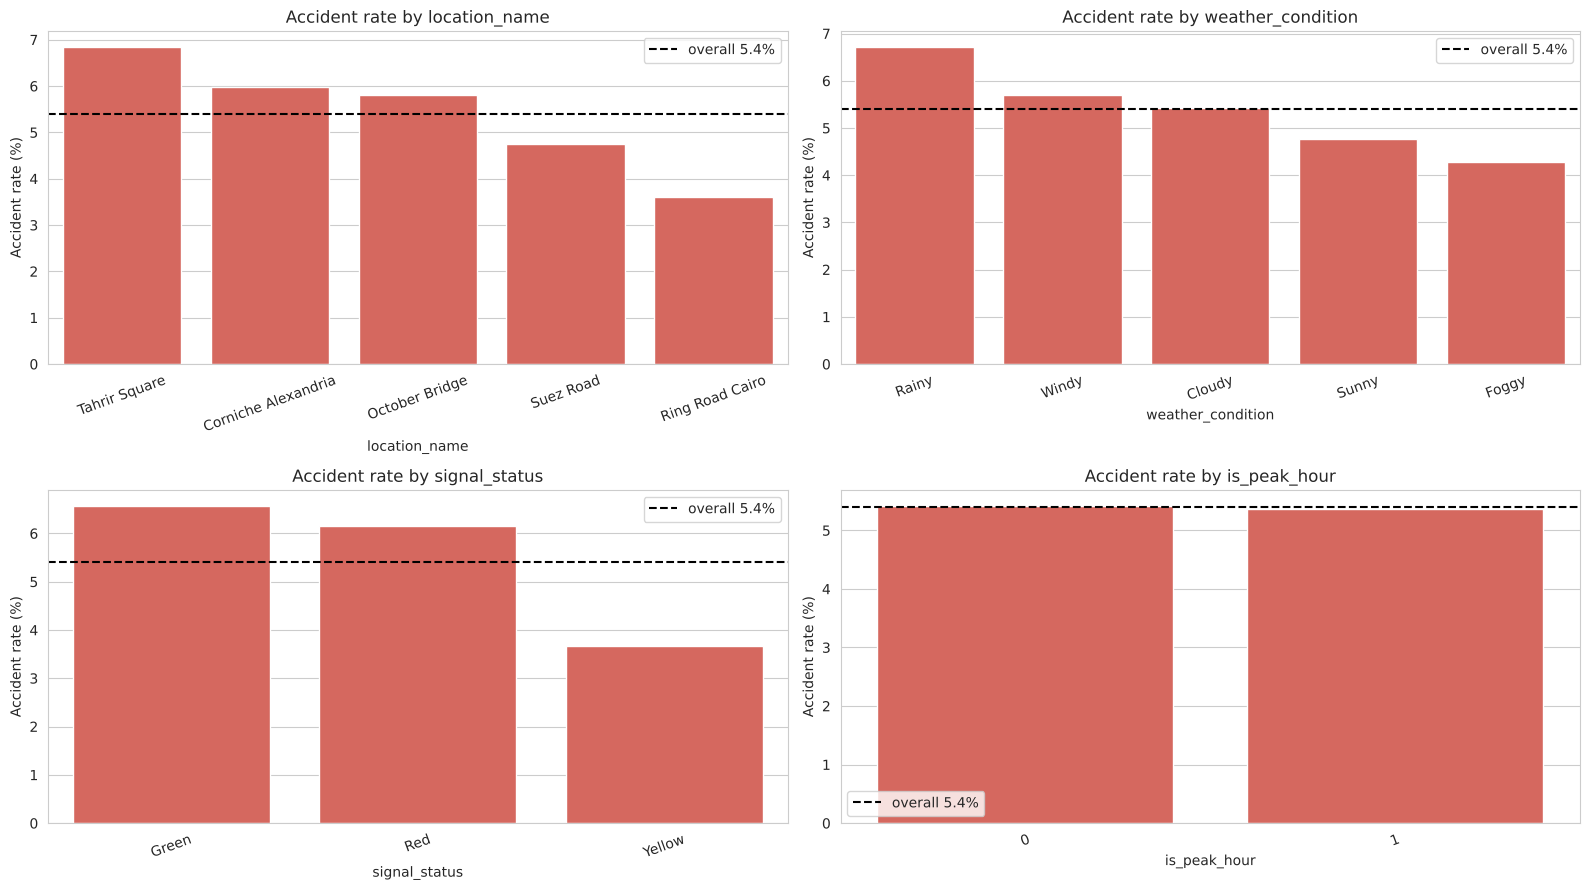

In [39]:
overall_rate = df['accident_reported'].mean() * 100
plt.figure(figsize=(16, 9))
for i, col in enumerate(['location_name', 'weather_condition', 'signal_status', 'is_peak_hour']):
    plt.subplot(2, 2, i + 1)
    rate = df.groupby(col)['accident_reported'].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, color='#E8574C')
    plt.axhline(overall_rate, color='black', linestyle='--', label=f'overall {overall_rate:.1f}%')
    plt.ylabel('Accident rate (%)')
    plt.title(f'Accident rate by {col}')
    plt.xticks(rotation=20)
    plt.legend()
plt.tight_layout()
plt.show()

In [40]:
# Chi-square test of independence (p < 0.05 = category and accident are related)
rows = []
for col in ['location_id', 'weather_condition', 'signal_status', 'is_peak_hour']:
    table = pd.crosstab(df[col], df['accident_reported'])
    rows.append([col, round(stats.chi2_contingency(table)[1], 3)])
pd.DataFrame(rows, columns=['feature', 'chi2_p_value'])

,feature,chi2_p_value
0,location_id,0.290
1,weather_condition,0.627
2,signal_status,0.038
3,is_peak_hour,1.000


In [41]:
pd.crosstab(df['signal_status'], df['accident_reported'], normalize='index').mul(100).round(1)

accident_reported,0,1
signal_status,,
Green,93.4,6.6
Red,93.9,6.1
Yellow,96.3,3.7


**Observation:**
- **`signal_status` is the only significant feature (p = 0.038):** the accident rate is **6.6 %** at Green and **6.1 %** at Red, but only **3.7 %** at Yellow. This is a weak association, and with only 108 accidents it should be read with caution.
- **Location:** Tahrir Square has the highest rate (6.8 %) and Ring Road Cairo the lowest (3.6 %), but p = 0.29 → not significant.
- **Weather:** Rainy has the highest rate (6.7 %) and Foggy the lowest (4.3 %), but p = 0.63 → not significant. Surprisingly, fog does not increase accidents here.
- **Peak hour vs off-peak:** no meaningful difference.

## 3. Feature-to-Feature Analysis

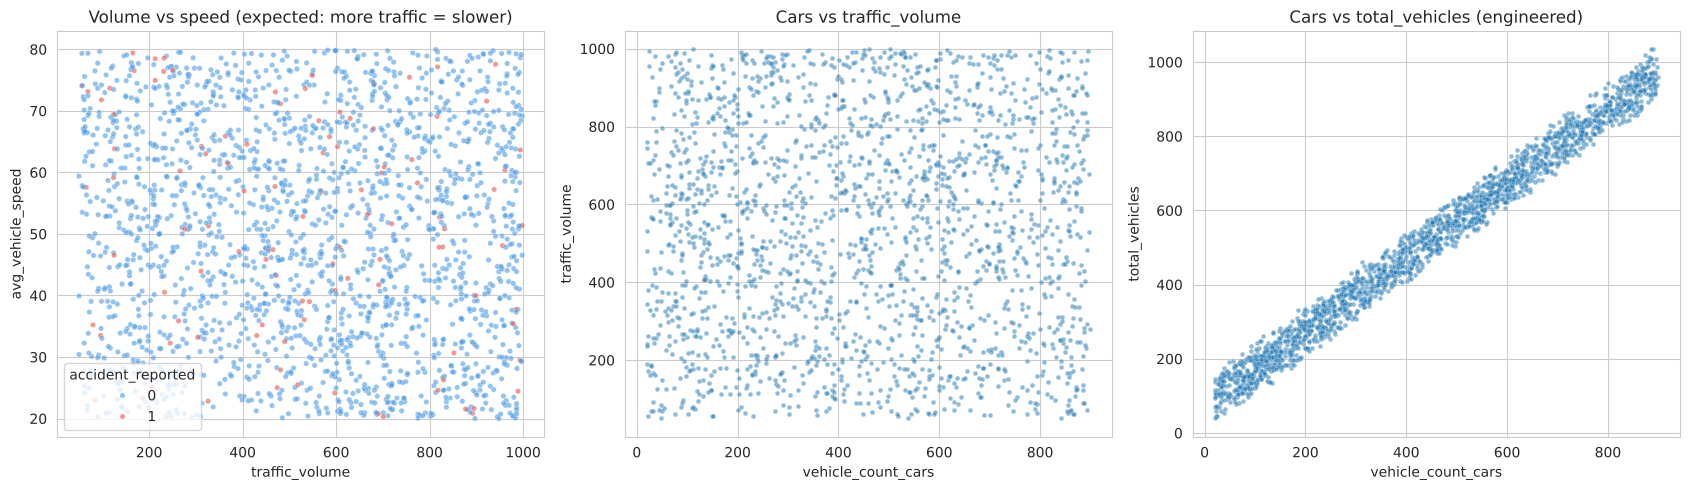

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(x='traffic_volume', y='avg_vehicle_speed', data=df, hue='accident_reported',
                palette=['#4C9BE8', '#E8574C'], alpha=0.6, s=15, ax=axes[0])
axes[0].set_title('Volume vs speed (expected: more traffic = slower)')
sns.scatterplot(x='vehicle_count_cars', y='traffic_volume', data=df, alpha=0.5, s=12, ax=axes[1])
axes[1].set_title('Cars vs traffic_volume')
sns.scatterplot(x='vehicle_count_cars', y='total_vehicles', data=df, alpha=0.5, s=12, ax=axes[2])
axes[2].set_title('Cars vs total_vehicles (engineered)')
plt.tight_layout()
plt.show()

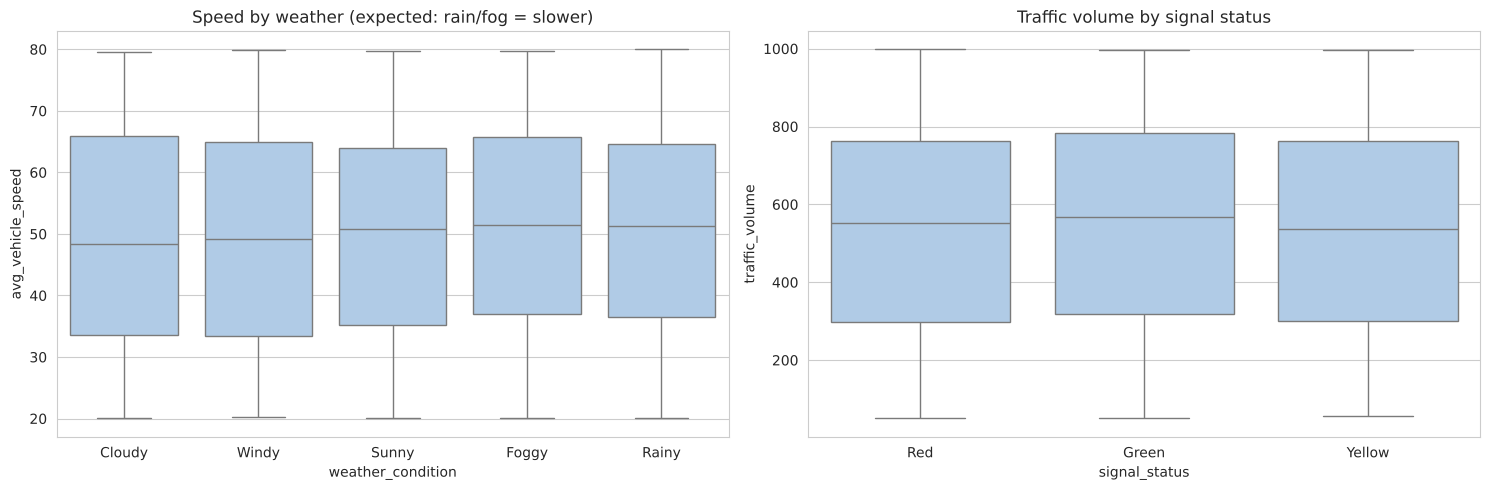

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(x='weather_condition', y='avg_vehicle_speed', data=df, color='#A7CBEF', ax=axes[0])
axes[0].set_title('Speed by weather (expected: rain/fog = slower)')
sns.boxplot(x='signal_status', y='traffic_volume', data=df, color='#A7CBEF', ax=axes[1])
axes[1].set_title('Traffic volume by signal status')
plt.tight_layout()
plt.show()

**Observation:**
- **Volume vs speed:** a random cloud, no downward trend. In real roads, heavy traffic lowers speed; here it does not. Accident points (red) are scattered everywhere, not in one corner.
- **Cars vs traffic_volume:** no relationship, which confirms the consistency finding from Data Cleaning.
- **Cars vs total_vehicles:** an almost perfect line (r ≈ 0.99) because cars make up most of the total. Using **both** in a model would add duplicate information (**multicollinearity**), so later we keep either the three counts **or** `total_vehicles`, not all four.
- **Weather vs speed:** the average speed is ≈ 49–51 km/h in every weather type, so rain and fog do **not** slow traffic in this dataset (another sign of synthetic data).

## 4. Correlation Analysis

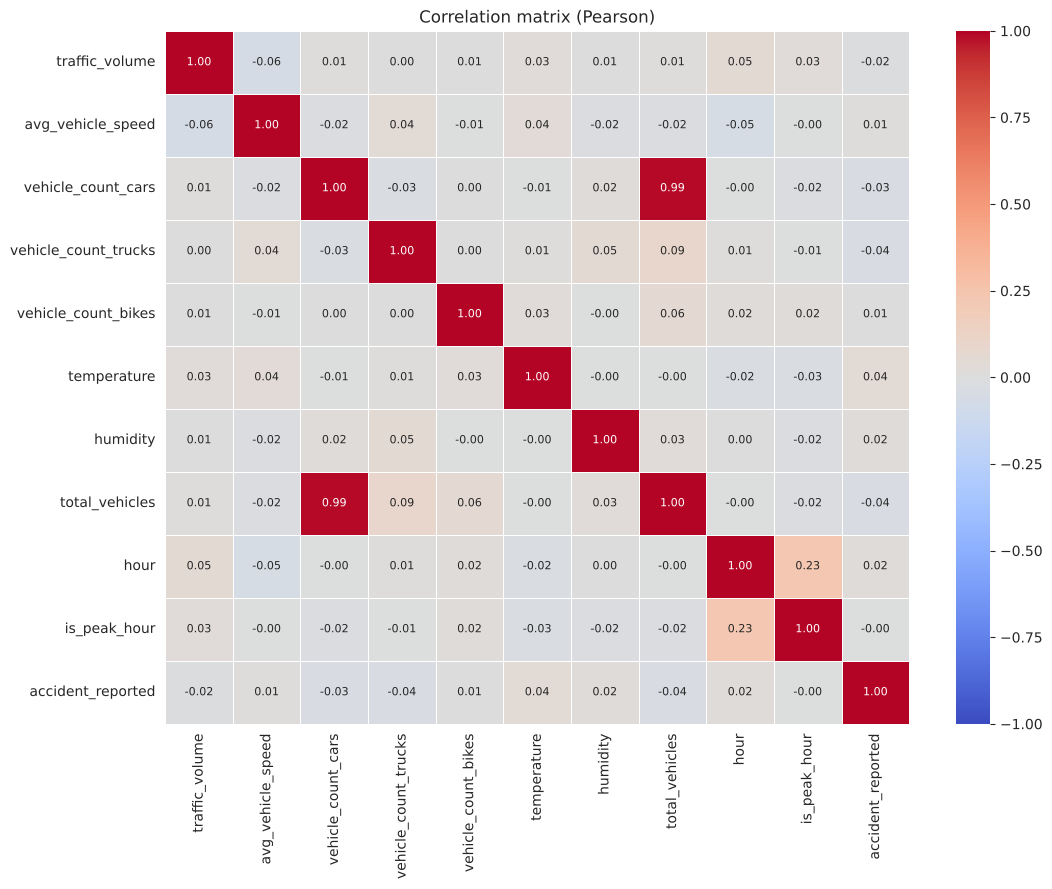

In [44]:
# location_id is left out: it is a category code, so a Pearson correlation on it has no meaning
corr_cols = uni_cols + ['hour', 'is_peak_hour', 'accident_reported']
corr = df[corr_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={'size': 8})
plt.title('Correlation matrix (Pearson)')
plt.show()

In [45]:
# Correlation of every feature with the target, strongest first
corr['accident_reported'].drop('accident_reported').sort_values(key=abs, ascending=False).round(3)

temperature             0.041
total_vehicles         -0.038
vehicle_count_trucks   -0.035
vehicle_count_cars     -0.035
hour                    0.019
humidity                0.016
traffic_volume         -0.015
avg_vehicle_speed       0.011
vehicle_count_bikes     0.007
is_peak_hour           -0.001
Name: accident_reported, dtype: float64

**Observation:**
- **Strength:** every correlation between *original* features is close to **0** (|r| < 0.1), so the features are almost independent of each other and there is no multicollinearity in the raw data.
- The only strong value is **cars ↔ total_vehicles = 0.99** (positive, very strong), and it exists only because we built `total_vehicles` from cars. Likewise **hour ↔ is_peak_hour = 0.23** is expected, because `is_peak_hour` is built from `hour`.
- `location_id` is not in the matrix because it is a category code; its link to the target was tested with chi-square instead.
- **With the target:** the strongest correlations are temperature (+0.04), total_vehicles (−0.04) and cars (−0.035). All are **very weak**. Positive means slightly more accidents when the value is higher; negative means slightly fewer.
- *Note:* Pearson measures only straight-line relationships. Weak linear correlation does not rule out non-linear patterns, which tree-based models (Decision Tree / Random Forest) can still detect.

## 5. GroupBy / Statistical Summary Analysis

In [46]:
# By location
df.groupby('location_name').agg(
    readings=('accident_reported', 'size'),
    accidents=('accident_reported', 'sum'),
    accident_rate_pct=('accident_reported', lambda s: s.mean() * 100),
    avg_volume=('traffic_volume', 'mean'),
    median_volume=('traffic_volume', 'median'),
    avg_speed=('avg_vehicle_speed', 'mean'),
).round(1).sort_values('accident_rate_pct', ascending=False)

,readings,accidents,accident_rate_pct,avg_volume,median_volume,avg_speed
location_name,,,,,,
Tahrir Square,409,28,6.8,537.2,549.0,49.1
Corniche Alexandria,401,24,6.0,550.7,581.0,50.4
October Bridge,396,23,5.8,543.0,552.0,48.7
Suez Road,379,18,4.7,522.5,526.0,51.0
Ring Road Cairo,415,15,3.6,550.2,540.0,50.9


In [47]:
# By weather
df.groupby('weather_condition').agg(
    readings=('accident_reported', 'size'),
    accidents=('accident_reported', 'sum'),
    accident_rate_pct=('accident_reported', lambda s: s.mean() * 100),
    avg_speed=('avg_vehicle_speed', 'mean'),
    avg_temperature=('temperature', 'mean'),
    avg_humidity=('humidity', 'mean'),
).round(1).sort_values('accident_rate_pct', ascending=False)

,readings,accidents,accident_rate_pct,avg_speed,avg_temperature,avg_humidity
weather_condition,,,,,,
Rainy,387,26,6.7,50.6,22.8,59.0
Windy,438,25,5.7,49.3,22.6,61.3
Cloudy,424,23,5.4,49.4,22.0,59.9
Sunny,378,18,4.8,49.9,22.4,59.9
Foggy,373,16,4.3,51.0,22.6,60.4


In [48]:
# By signal status
df.groupby('signal_status').agg(
    readings=('accident_reported', 'size'),
    accidents=('accident_reported', 'sum'),
    accident_rate_pct=('accident_reported', lambda s: s.mean() * 100),
    avg_volume=('traffic_volume', 'mean'),
    avg_speed=('avg_vehicle_speed', 'mean'),
).round(1).sort_values('accident_rate_pct', ascending=False)

,readings,accidents,accident_rate_pct,avg_volume,avg_speed
signal_status,,,,,
Green,609,40,6.6,551.8,50.1
Red,683,42,6.1,538.9,49.8
Yellow,708,26,3.7,533.6,50.1


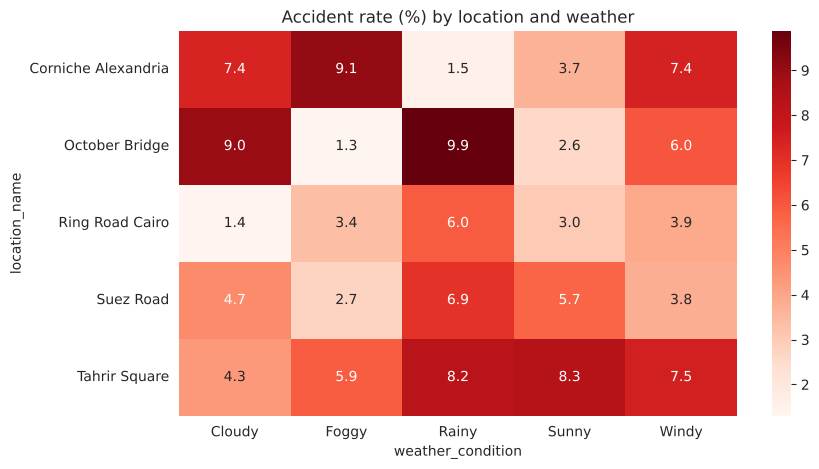

In [49]:
# Location x Weather accident rate (%)
pivot = df.pivot_table(index='location_name', columns='weather_condition',
                       values='accident_reported', aggfunc='mean').mul(100)
plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Reds')
plt.title('Accident rate (%) by location and weather')
plt.show()

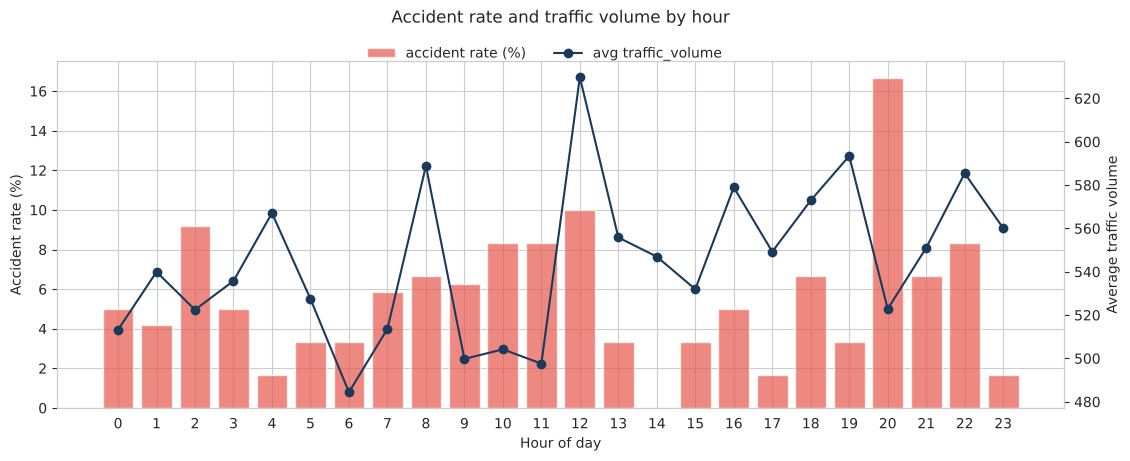

In [50]:
# By hour of day
hourly = df.groupby('hour').agg(accident_rate=('accident_reported', 'mean'),
                                avg_volume=('traffic_volume', 'mean'))
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.bar(hourly.index, hourly['accident_rate'] * 100, color='#E8574C', alpha=0.7, label='accident rate (%)')
ax1.set_xlabel('Hour of day'); ax1.set_ylabel('Accident rate (%)')
ax2 = ax1.twinx()
ax2.plot(hourly.index, hourly['avg_volume'], color='#1a3a5c', marker='o', label='avg traffic_volume')
ax2.set_ylabel('Average traffic volume')
ax2.grid(False)
ax1.set_xticks(range(24))
plt.title('Accident rate and traffic volume by hour', pad=28)
fig.legend(loc='upper center', ncol=2, bbox_to_anchor=(0.5, 0.94), frameon=False)
plt.show()

**Observation:**
- **Location:** Tahrir Square has the most accidents (28 of 409, 6.8 %) and Ring Road Cairo the fewest (15 of 415, 3.6 %). Average volume and speed are almost the same everywhere.
- **Weather:** Rainy leads (6.7 %), Foggy is lowest (4.3 %). Average speed stays ≈ 50 km/h in every weather type.
- **Signal:** Green 6.6 % > Red 6.1 % > Yellow 3.7 %, the same pattern as the chi-square result.
- **Location × weather:** some cells look high (the darkest cells), but each cell has only about 70–90 readings and a few accidents, so these numbers are **unstable** and should not be over-interpreted.
- **Hour:** the accident rate jumps around from hour to hour (between 0 accidents at 14:00 and 10 at 20:00) with no clear rush-hour peak. Average traffic volume also moves up and down (≈ 480–630) without a morning/evening rush pattern.

## Save the cleaned dataset

In [51]:
clean_cols = ['timestamp', 'hour', 'is_peak_hour', 'location_id', 'location_name',
              'traffic_volume', 'avg_vehicle_speed', 'vehicle_count_cars', 'vehicle_count_trucks',
              'vehicle_count_bikes', 'total_vehicles', 'weather_condition', 'temperature',
              'humidity', 'signal_status', 'accident_reported']
df[clean_cols].to_csv('Dataset/traffic_cleaned_task1.csv', index=False)
print('Saved:', df[clean_cols].shape)

Saved: (2000, 16)


# 4) Summary of Main Findings

**Data understanding**
- 2,000 readings × 12 columns, one per minute over ≈ 33 hours at 5 locations.
- Binary target `accident_reported` is **highly imbalanced: 94.6 % / 5.4 %** (1,892 vs 108). Accuracy will be misleading, so later we use **precision / recall / F1**, a **stratified** split and **class weights or resampling**.

**Data cleaning — every decision**
| Check | Result | Decision |
|---|---|---|
| Missing values | 0 | No imputation needed (median/mode plan documented) |
| Duplicates | 0 (also 0 ignoring timestamp) | Nothing removed |
| `timestamp` type | text | Converted to datetime; extracted `hour`, `is_peak_hour` |
| `location_id` | numeric code | Treated as categorical; added `location_name` label |
| `traffic_volume` vs counts | do not match (48 % of rows counts > volume) | Kept both; documented as a limitation |
| Outliers (IQR, Z-score, LOF, domain check) | 0 | **Ignore / keep** — remove, cap and transform would change nothing |

**EDA**
- All numeric features are **uniformly distributed** (flat, symmetric, not normal).
- Original features are **almost uncorrelated** with each other and with the target (all |r| < 0.05 with `accident_reported`).
- **Only `signal_status` is significantly related to accidents** (p = 0.038): Yellow 3.7 % vs Green 6.6 %.
- Expected real-world patterns are missing: heavy traffic does not reduce speed, rain/fog do not reduce speed, and fog does not raise accidents.
- `total_vehicles` ≈ `vehicle_count_cars` (r = 0.99) → avoid using both in one model.

**What this means for the next tasks**
1. The weak signal suggests the dataset is **synthetic**, so we should expect **modest model performance**. A good result means **beating a baseline** on recall/F1, not reaching high accuracy.
2. Preprocessing still to do: one-hot encode `location_id`, `weather_condition`, `signal_status`; scale numeric features for KNN; drop `timestamp`, `location_name` and either `total_vehicles` or the separate counts.
3. Handle the 17.5 : 1 imbalance before or during training.